# Data Descriptive of YouNiverse

In [15]:
# Importing Libraries

from src.data.loader import *
from src.data.quality_check import *
from src.utils.paths import DATA_DIR, DATASET_CHANNELS, PROCESSED_DATA_DIR

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set seaborn style and color palette
sns.set_palette("husl")
sns.set_style("whitegrid")

# Random seed to make the code reproducible
seed=6

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Data Exploration


Our Project will need data from these datasets:
- `df_channels.tsv.gz`: Channel data.
- `df_timeseries.tsv.gz` : Channel data over time including `delta views`, `delta_videos` and `delta_subs`.
- `yt_metadata_en.jsonl.gz` : Metadata for each video
- `num_comments.tsv.gz` : Number of comments per video.
- `yt_metadata_helper.feather` : A lighter version of video metadata not including description, titles and tags.

Before proceeding please make sure these `data/raw` folder.

To get a better feel for the datasets, we begin by inspecting each of the datasets.
Our goal in this section is to understand structure, size and feasibility of working with the raw data.

### I. Loading Raw Data

Because loading all the data at the same time is not possible in a 16GB local machine, <br>
we load a subset of a maximum 1 million rows per dataset.

In [2]:
subset_size = 1_000_000
channels_df, videos_df, videos_light_df, timeseries_df, num_comments_df = load_all_raw_datasets(nrows=subset_size)

### II. Checking data quality

Before deciding on pre-processing the data, it is important to take a look at the quality metrics.

In [3]:
df_list = [channels_df,
           videos_df,
           videos_light_df,
           timeseries_df,
           num_comments_df]

names = ["Channels", "Videos", "Videos (Light)", "Timeseries", "Num Comments"]

check_data_quality_on_datasets(df_list, names)

,Dataset,Rows,Columns,Missing %,Duplicate %,Memory (MB),Numeric Cols,Categorical Cols,Non-Null % (avg),Unique % (avg),Min Numeric,Max Numeric
1,Videos,1000000,8,0.49,0.0,244.93,4,4,99.51,15.34,0.0000,1.101396e+09
2,Videos (Light),1000000,12,0.33,0.0,2447.37,4,8,99.67,38.61,0.0000,1.101396e+09
3,Timeseries,1000000,10,0.01,0.0,267.69,7,3,99.99,32.20,0.0000,1.334730e+10
4,Num Comments,1000000,2,0.00,0.0,72.48,1,1,100.00,50.40,0.0000,2.231960e+05
0,Channels,136470,8,0.01,0.0,41.43,4,4,99.99,42.90,2.0865,1.121395e+08


The quick quality report tells us there are not a lot of missing values. However, we should be aware of that.

### III. Correlation matrix

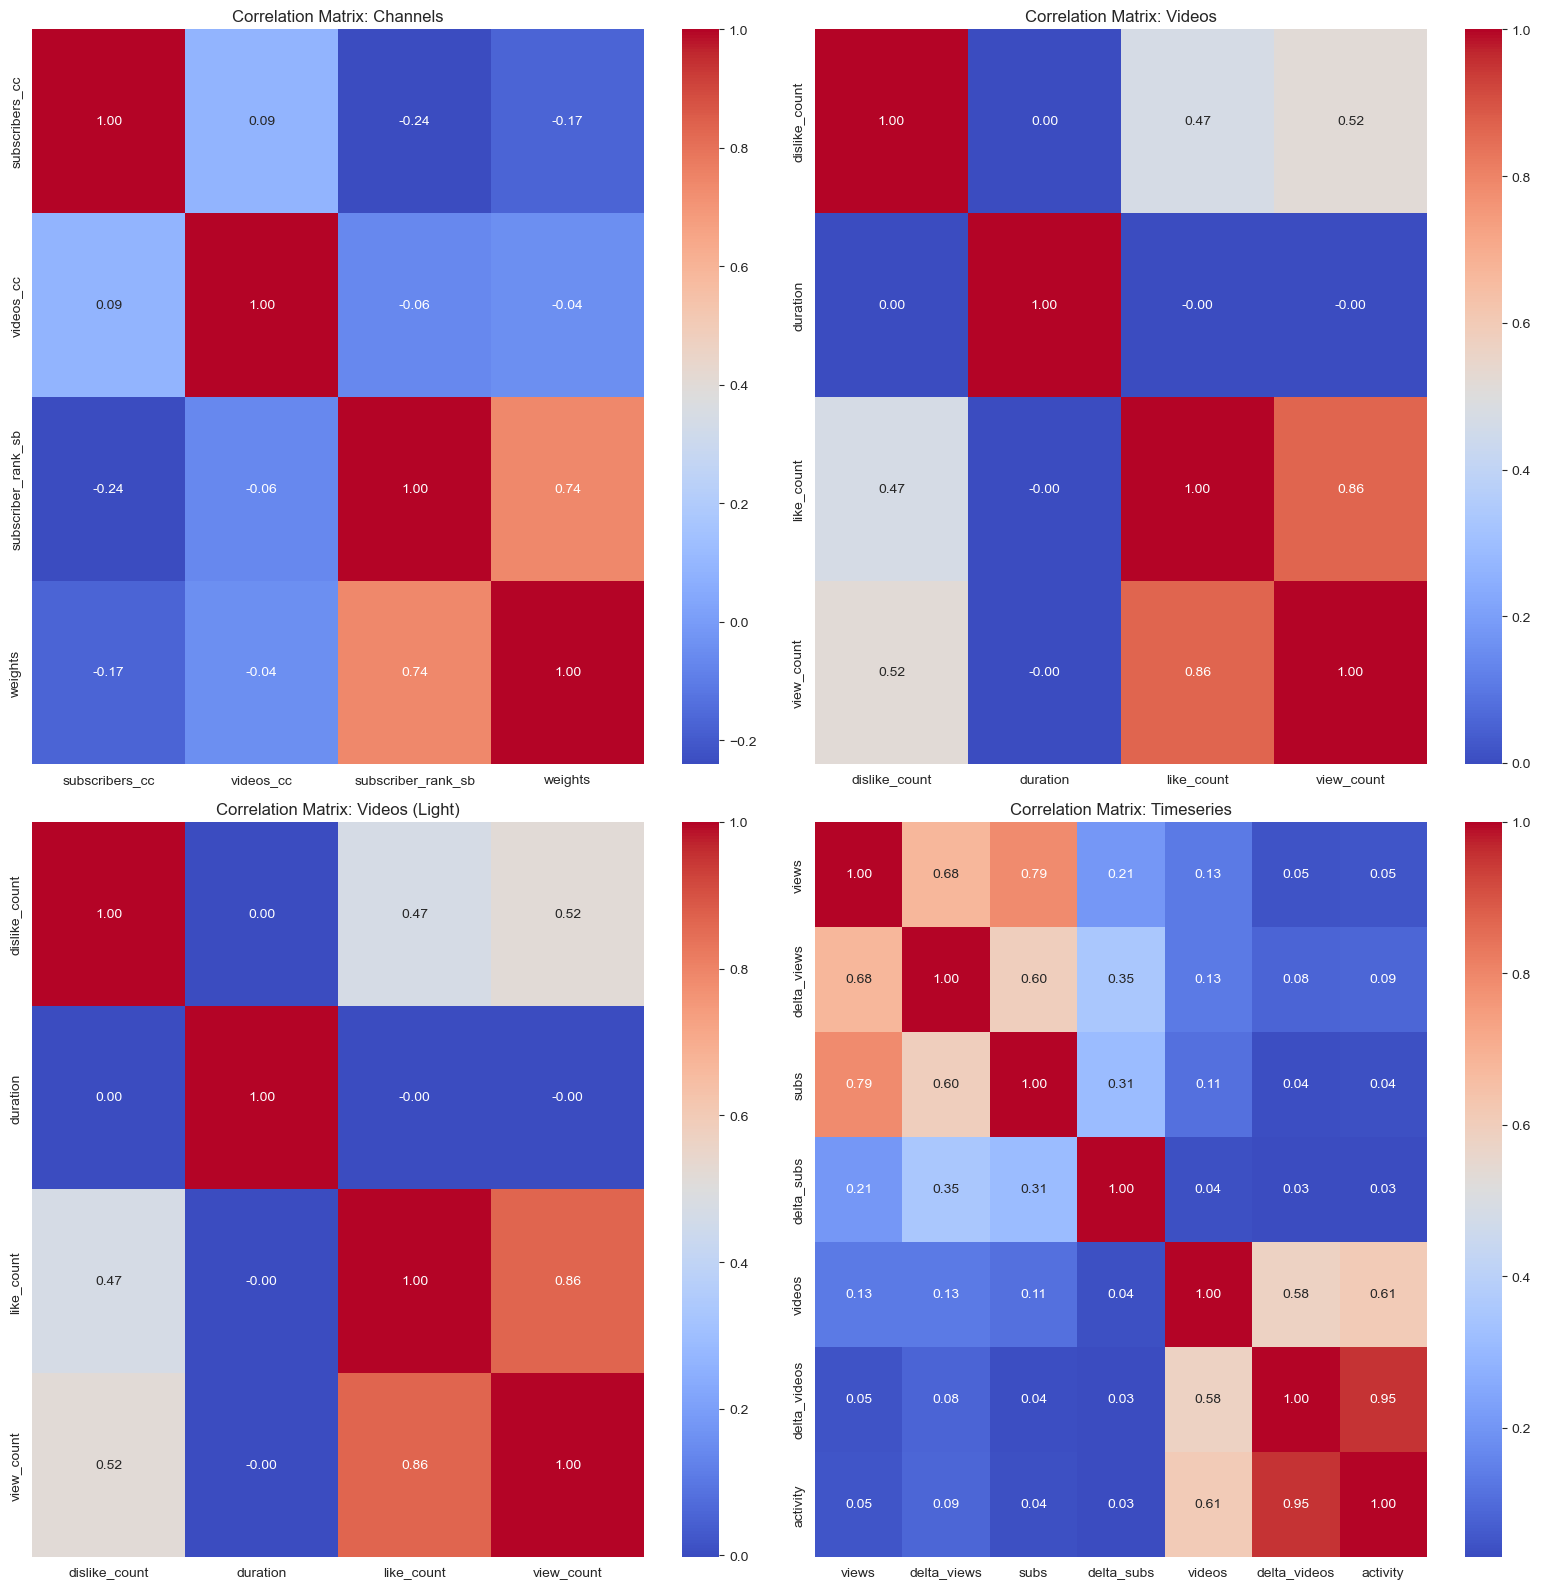

In [16]:
# Function to plot correlation matrix
def plot_correlation_matrix(ax, df, title):
    corr = df.corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, ax=ax)
    ax.set_title(title)


# Filter out the 'Num Comments' dataframe
filtered_df_list = [df for df, name in zip(
    df_list, names) if name != "Num Comments"]
filtered_names = [name for name in names if name != "Num Comments"]

# Create subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 16))

# Plot correlation matrices
for ax, df, name in zip(axes.flatten(), filtered_df_list, filtered_names):
    numeric_cols = df.select_dtypes(
        include=['float64', 'int64'])  # Select numeric columns
    if not numeric_cols.empty:  # Only plot if there are numeric columns
        plot_correlation_matrix(
            ax, numeric_cols, f"Correlation Matrix: {name}")

plt.tight_layout()
plt.show()

### III. Decisions on Data Preprocessing

 // THis includes feature engineering

We preprocess each dataset and save the cleaned outputs for later use. <br>
The following steps are taken in align with the project goals, code is located in `src/data/preprocessing.py`
- For each dataset, duplicates are dropped, formats are changed and missing values are filled respectively.
- We enrich the `channels_df` with additional columns:
  - `total_likes` — total likes from all videos of the channel
  - `total_views`
  - `total_views` — cumulative view count across all videos
  - `avg_efficiency` — average engagement efficiency across the channel’s videos
  - `upload_frequency` — number of uploads in the last 6 months
- We create filtered and preprocessed versions of `videos_df` and `timeseries_df` to ensure temporal consistency and reduce storage size.
- Each cleaned dataset is saved under the `/data/processed/` directory for subsequent analysis.


# Jon -> continue docummenting this. Dont over document cause that is in Readme, here just a short desc


In [4]:
# Code for running the pipeline
from src.data.preprocessing_new import apply_data_processing

## 2. Loading the data

In [5]:
apply_data_processing()

STEP 1: Loading existing num_comments (already processed)

STEP 2: video_light already processed, skipping
  Path: /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet

STEP 3: Loading existing channels (already processed)
  Shape: (136470, 18)

STEP 4: timeseries already processed, skipping
  Path: /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/timeseries_processed.parquet

DATA PROCESSING COMPLETE!
All processed files saved to: /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed

Processed files:
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/num_comments_processed.parquet
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/channels_processed.parquet
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/timeseries_proc

{'channels': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/channels_processed.parquet',
 'timeseries': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/timeseries_processed.parquet',
 'videos_light': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet',
 'num_comments': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/num_comments_processed.parquet'}

In [24]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(5)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.859855,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.932584,40549


In [25]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,...,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,...,1437.0,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,...,1437.0,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,...,1437.0,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,...,1437.0,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,...,1437.0,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189


In [ ]:
# Not reading videos directly as it is too large

# 3. Basic information about the data

## I. Subscribers distribution

As our research is focused on working with small- to midsize-channels, it is important to understand overall image of subscribers count.

In [10]:
channel_df = pd.read_parquet(os.path.join(PROCESSED_DATA_DIR, 'channels_processed.parquet'))
channel_df.head(5)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.859855,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.932584,40549


To provide more accurate distribution, we leverage `weights` data from the dataset for normalization.

In [11]:
from src.utils.general_utils import weighted_percentiles, weighted_percentile_of_value

cuts = weighted_percentiles(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    percentiles=(50, 90)
)
print(cuts)
p50, p90 = cuts[50], cuts[90]

{50: 22200.0, 90: 160000.0}


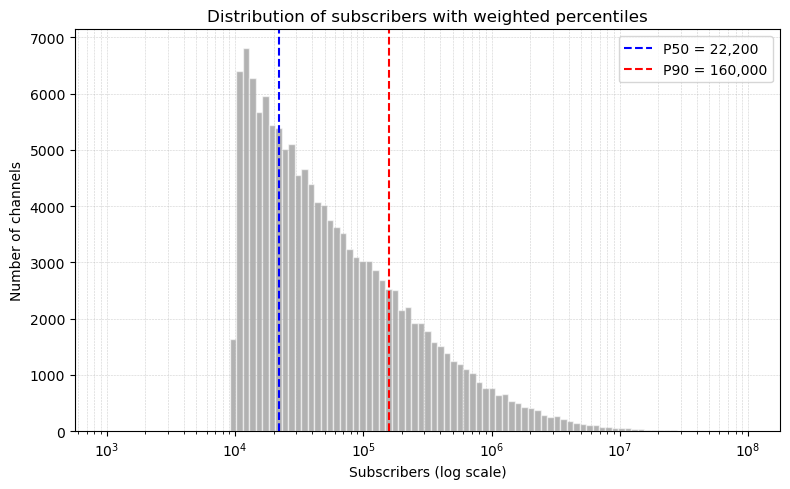

In [12]:
# Plotting this distribution to get a better feel
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))
plt.hist(
    channel_df["subscribers_cc"],
    bins=np.logspace(3, 8, 100),     # log-spaced bins from 1e3 to 1e8
    color="gray",
    alpha=0.6,
    edgecolor="white"
)
plt.axvline(p50, color="blue", linestyle="--",
            linewidth=1.5, label=f"P50 = {p50:,.0f}")
plt.axvline(p90, color="red", linestyle="--",
            linewidth=1.5, label=f"P90 = {p90:,.0f}")

plt.xscale("log")
plt.xlabel("Subscribers (log scale)")
plt.ylabel("Number of channels")
plt.title("Distribution of subscribers with weighted percentiles")
plt.grid(True, which="both", ls="--", lw=0.4, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# 4. Detecting Outperformers

### Identifying small to mid sized channels

To identify these sizes of channels, lets first look at the distribution of channels based on subscribers.

Since the subscriber count is heavy tailed along the higher number of subscribers we labeled small channels in 50%, and the mid sized channels from 50% to 90% of the channel distribution.

In [18]:
# Now we filter and keep the channels that are small to mid sized

# small_mid_sized_channels_df =channel_df[channel_df["subscribers_cc"] <= p90].copy()

small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### Fitting the model and detecting the outperformers

**Engagement efficiency (video level):**
For each video *v* Engagement efficiency is defined as:
`E_v = (likes_v + comments_v) / views_v`

**Channel-level efficiency** is the average efficiency over all videos of a channel *c*:
`E_c = (Σ(likes_v + comments_v)) / Σ(views_v)`

**Expected efficiency model (log–log linear regression):**
We model how efficiency changes with channel size:
`log10(E_c) = a + b * log10(subscribers_c) + ε_c`
This stabilizes heavy-tailed data and makes the relationship roughly linear.

**Why log–log?**
YouTube metrics vary by orders of magnitude; logs reduce skew and make trends clearer.

**Residuals (deviation from expectation):**
`r_c = log10(E_c) - (a + b * log10(subscribers_c))`

**Quiet outperformers:**
Channels with residuals above a threshold γ (e.g., mean + 2·std or top 5%) are labeled as outperformers:
`if r_c > γ → quiet outperformer`



In [19]:
from src.models.log_log_efficiency_model import linear_log_log_model

channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    gamma_z=2.0,
    log_base=10,
    verbose=True,
)

channels_model.head(5)

 log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)
   Outliers (z>2.0): 719/94362 (0.76%)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore,is_outlier
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,2266.0,29914.0,0.986781,16,4.992111,-1.164280,-1.613989,0.449709,1.233636,False
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,19153.0,13512.0,0.978910,267,4.965202,-1.488122,-1.610172,0.122050,0.341271,False
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,5360.0,8565.0,0.965106,35,4.994242,-1.531054,-1.614292,0.083238,0.235570,False
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,13301.0,12879.0,0.970602,52,4.992120,-1.529482,-1.613991,0.084508,0.239030,False
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,17840.0,2423.0,0.899380,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900,False


In [20]:
outperformers = channels_model[channels_model["is_outlier"]]


print(len(outperformers))
outperformers.head(300)

719


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore,is_outlier
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,...,20696.0,65870.0,0.968095,181,4.924538,-0.792110,-1.604403,0.812293,2.221115,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,...,9496.0,104127.0,0.995255,340,4.866878,-0.819539,-1.596224,0.776685,2.124138,True
36916,Sports,2018-12-07,UCfFQyv0h5WwZ_mu7YXYj31w,Chomno Bro Game,94700,255,127798.0,3.9435,324.0,0.787037,...,15933.0,41280.0,0.978606,258,4.976350,-0.771467,-1.611753,0.840287,2.297355,True
39763,Gaming,2015-01-19,UCqIkw8jGmjBjbpG0Yc-62BA,CuBeLightning,72500,207,141769.0,5.3315,1742.0,0.118829,...,10376.0,11713.0,0.852868,208,4.860338,-0.855285,-1.595296,0.740011,2.024259,True
41375,Autos & Vehicles,2017-10-14,UC6bGyzeqFtlTKDOeSw6ZcAA,Asad Talha,75300,303,148537.0,4.5195,743.0,0.407806,...,13052.0,15954.0,0.668831,309,4.876795,-0.855740,-1.597630,0.741891,2.029378,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96658,Gaming,2017-01-01,UCZA8Q6vPCX3EfQSdHC26CnA,Halobombtrooper Gami...,19400,762,515377.0,9.4390,1029.0,0.740525,...,5773.0,33504.0,0.940369,760,4.287802,-0.747271,-1.514075,0.766804,2.097229,True
96712,Howto & Style,2015-02-06,UCjEyVN4CvHb1JFEu1HdSvNA,My Fun Place,21700,90,515938.0,9.4475,1724.0,0.052204,...,7414.0,3175.0,0.952680,89,4.336460,-0.665680,-1.520978,0.855298,2.338236,True
97251,Comedy,2011-10-04,UC5GqcldXksgjMTtdYMcSS5g,Music Is A Rainbow,21700,546,521638.0,10.1185,2945.0,0.185399,...,2948.0,44737.0,0.978612,552,4.336460,-0.697316,-1.520978,0.823661,2.252076,True
97451,People & Blogs,2018-07-22,UCs73CHuMxlBB2Sq9hF5_ReA,Muneercoolkidd Gamer...,21100,315,524304.0,11.0485,462.0,0.681818,...,1981.0,7711.0,0.805378,291,4.324282,-0.717625,-1.519250,0.801625,2.192062,True


In [32]:
outperformers = channels_model[channels_model["is_outlier"]].sort_values(
    by="subscribers_cc", ascending=True)

normal_performers = channels_model[~channels_model["is_outlier"]].sort_values(
    by="subscribers_cc", ascending=True)

print(len(outperformers))
outperformers.head(10)

719


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore,is_outlier
134651,Gaming,2018-01-10,UC01BXM3HTneoEiimOKj5j2g,SuperNova GamePro Gi...,10000,187,927075.0,21.2005,655.0,0.285496,...,742.0,25298.0,0.945329,187,4.000000,-0.446928,-1.473247,1.026319,2.804005,True
133897,Science & Technology,2012-11-14,UC-sQ0P6uSCe3vqWmzN_WSBw,DudetECH,10000,556,916328.0,16.3215,2538.0,0.219070,...,5071.0,6668.0,0.914076,569,4.000000,-0.552283,-1.473247,0.920964,2.517075,True
133454,Gaming,2016-05-22,UC-3UK-xM8oBJuYp1T0YB7Pg,Resqwad,10000,397,906030.0,14.9640,1253.0,0.316840,...,580.0,2780.0,0.950028,397,4.000000,-0.733346,-1.473247,0.739902,2.023961,True
124247,Gaming,2015-01-16,UCd2d4ljgQ1FjwQ0XNJKB1tA,Tum,10000,292,788324.0,9.8705,1745.0,0.167335,...,577.0,16169.0,0.970390,296,4.000000,-0.686213,-1.473247,0.787034,2.152323,True
133420,Gaming,2015-07-12,UCPpQnMb7d3MGYZmjFUVnuWQ,Mr. Brunswick,10000,161,905996.0,14.7320,1568.0,0.102679,...,84.0,3189.0,0.987855,164,4.000000,-0.717410,-1.473247,0.755837,2.067360,True
135238,Entertainment,2012-08-29,UCy5BM1C99Z_Xz-ozGS82xnA,Sandra's haul's,10000,707,937304.0,27.6795,2615.0,0.270363,...,4362.0,163208.0,0.973532,720,4.000000,-0.499081,-1.473247,0.974167,2.661969,True
135319,People & Blogs,2017-03-14,UCUsUGoguLcAiQGEnH9tWULA,Lil Honey,10000,108,938429.0,28.8235,957.0,0.112853,...,907.0,2024.0,0.856060,108,4.000000,-0.597489,-1.473247,0.875758,2.393960,True
136463,Entertainment,2016-11-08,UCf0RCfzyKoGr5AnLldeI1xw,On The Marc,10028,307,1007560.0,53.1435,1083.0,0.283472,...,3429.0,23050.0,0.919560,308,4.001214,-0.734033,-1.473420,0.739387,2.022559,True
134919,Entertainment,2014-01-16,UC9AaYXbH5qvbYSccHhiCWZQ,Hopping Berry Borer,10036,187,931081.0,23.4805,2110.0,0.088626,...,300.0,0.0,0.942372,186,4.001561,-0.528370,-1.473469,0.945099,2.582806,True
135688,Music,2017-11-07,UCaZjdivfF2G9Mtu4V32vbZw,skriansi music,10088,292,960435.0,53.1435,719.0,0.406120,...,13.0,1376.0,0.939209,300,4.003805,-0.728591,-1.473787,0.745196,2.038379,True


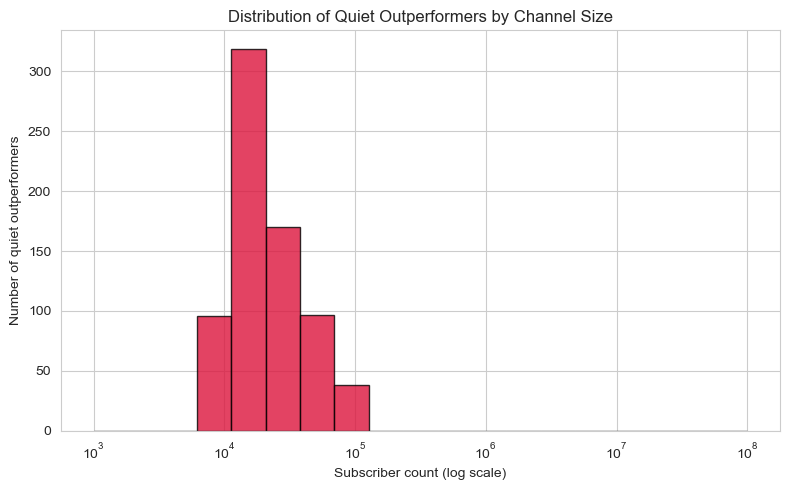

In [22]:
import matplotlib.pyplot as plt
import numpy as np


def plot_outperformer_distribution(df, subscribers_col="subscribers_cc", outperformer_col="is_outlier",
                                   bins=None, log_scale=True):
    """
    Plot the distribution of quiet outperformers across subscriber count ranges.

    X-axis: subscriber count (binned)
    Y-axis: number of outperformers in each bin
    """

    # Default: log-spaced bins from 1k to 100M subs
    if bins is None:
        bins = np.logspace(3, 8, 20)

    # Filter valid
    valid = df[df[subscribers_col] > 0]
    outp = valid[valid[outperformer_col]]

    # Histogram of outperformers
    counts, bin_edges = np.histogram(outp[subscribers_col], bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.figure(figsize=(8, 5))
    plt.bar(centers, counts, width=np.diff(bin_edges), align="center",
            alpha=0.8, edgecolor="black", color="crimson")

    if log_scale:
        plt.xscale("log")

    plt.xlabel("Subscriber count (log scale)")
    plt.ylabel("Number of quiet outperformers")
    plt.title("Distribution of Quiet Outperformers by Channel Size")
    plt.tight_layout()
    plt.show()


plot_outperformer_distribution(channels_model)

#### Categories of quiet outperformers

Initially, dataset provides us a correspondance of each channel to 1 of 16 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data_

<Figure size 1400x600 with 0 Axes>

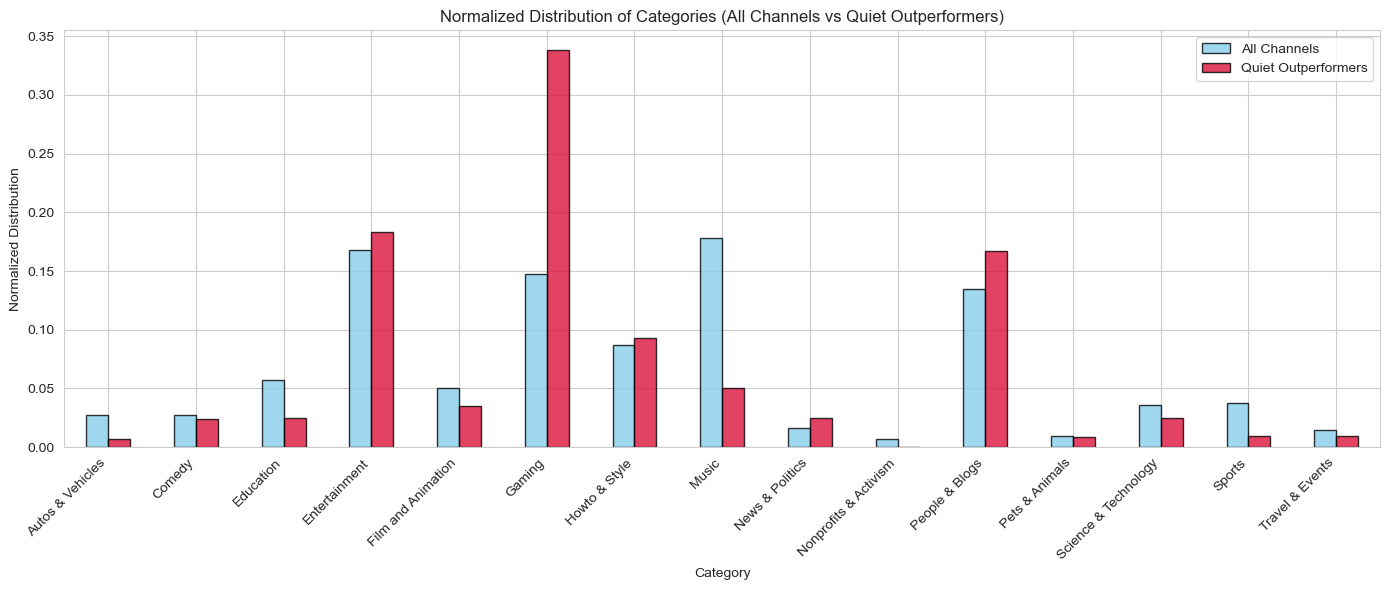

In [48]:
# Plot normalized distribution of categories for all channels and outperformers on the same plot
plt.figure(figsize=(14, 6))

# Normalize the counts to show distribution
channel_categories_norm = channel_df['category_cc'].value_counts(normalize=True)
outperformer_categories_norm = outperformers['category_cc'].value_counts(normalize=True)

# Combine both distributions into a single DataFrame for plotting
combined_df = pd.DataFrame({
    'All Channels': channel_categories_norm,
    'Quiet Outperformers': outperformer_categories_norm
}).fillna(0)  # Fill missing categories with 0

# Plot the combined normalized distributions
combined_df.plot(kind='bar', color=['skyblue', 'crimson'], edgecolor='black', alpha=0.8, figsize=(14, 6))

plt.xlabel('Category')
plt.ylabel('Normalized Distribution')
plt.title('Normalized Distribution of Categories (All Channels vs Quiet Outperformers)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

Let's tak a look on one random outperformer channel

In [49]:
channel = 'UC9AaYXbH5qvbYSccHhiCWZQ'  # Example channel ID
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]

channel_timeseries.head(5)



,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,...,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
2976658,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-10-17 00:00:00,477.500000,87.500000,12.250000,0.000000,16,0,6,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976659,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-10-24 00:00:00,594.500000,117.000000,15.000000,2.750000,17,1,3,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976660,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-10-30 23:00:00,693.321244,98.821244,18.119171,3.119171,18,1,3,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976661,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-11-06 23:00:00,807.057292,113.736048,20.489583,2.370412,19,1,2,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976662,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-11-13 23:00:00,991.322531,184.265239,22.106481,1.616898,23,4,6,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186


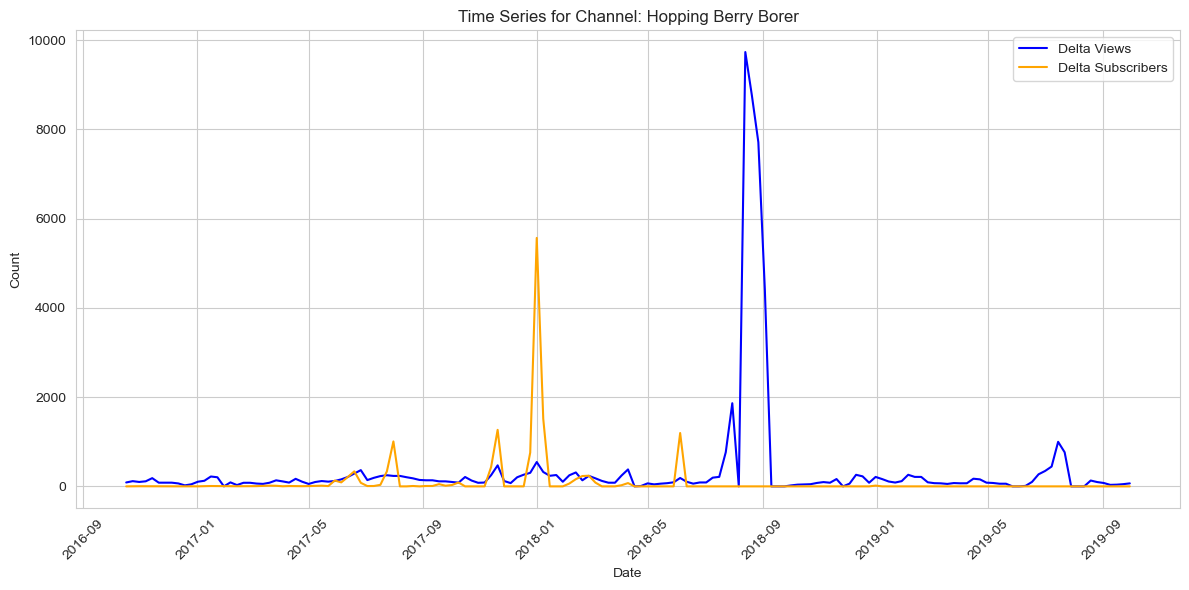

In [50]:
# plot
plt.figure(figsize=(12, 6))
plt.plot(channel_timeseries['datetime'],
         channel_timeseries['delta_views'], label='Delta Views', color='blue')
plt.plot(channel_timeseries['datetime'],
         channel_timeseries['delta_subs'], label='Delta Subscribers', color='orange')
plt.xlabel('Date')
plt.ylabel('Count')
plt.title(f'Time Series for Channel: {channel_df[channel_df["channel"] == channel]["name_cc"].values[0]}')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()